# Calibrated short-rate paths and their distribution

A one-factor Hull–White model describes future short rates using mean
reversion and a Gaussian volatility process. We calibrate its volatility
schedule to ATM caplet prices from the illustrative 24 February 2026 SOFR
market, generate 2,048 paths on a monthly five-year grid, and inspect the
resulting rate distribution.

Mean reversion is $\alpha=0.05$. The numerical generator evolves a centered
factor by Euler steps:

$$x_{i+1}=(1-\alpha\Delta t_i)x_i+
\sigma(t_{i+1})\sqrt{\Delta t_i}Z_i,\qquad r_i=x_i+\phi_i.$$

The shift uses the initial curve and a variance recursion. We reconstruct the
implemented moments below to separate sampling variation from time-grid
error. Returned values are decimal short rates under the pricing model.
This low-level generator requires positive $\alpha$.
[Setup](../README.md).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market, read_configuration

market = load_market()
ref = market.quotes.reference_date
simulation_spec = read_configuration("hullwhite", "simulation.json")
simulation_spec


{'market_index': 'SOFR',
 'model': {'HullWhite': {'alpha': 0.05,
   'parameter_source': {'Calibrated': {'source': {'Surface': {'market_index': 'SOFR'}},
     'calibration_basket': {'strike': 'Atm'}}}}},
 'n_paths': 2048,
 'seed': 42,
 'horizon': '5Y',
 'frequency': 'Monthly',
 'day_counter': 'Actual365'}

## Read the model specification as a set of financial choices

[simulation.json](data/simulation.json) contains the nested serialization
schema so it does not dominate the example. Its fields mean:

| Field | Meaning in this example |
| --- | --- |
| `market_index` | SOFR identifies the curve being simulated |
| `HullWhite.alpha` | Mean reversion, 0.05 per year |
| `parameter_source.Calibrated` | Fit a volatility schedule to the constructed market |
| `source.Surface` / `strike: Atm` | Use ATM caplet prices inferred from the SOFR Black surface |
| `horizon` / `frequency` | Five years of monthly output dates |
| `n_paths` / `seed` | 2,048 paths and a reproducible random-number sequence |
| `day_counter` | Actual/365 time coordinates |

The calibration translates Black caplet quotes into an absolute short-rate
volatility schedule. Substituting a quoted Black vol directly as `sigma` would
change the meaning of the model. You can change the path count or observation
frequency independently of the calibration source.

In [2]:
simulation_config = qs.SimulationConfiguration.from_dict(
    {
        **simulation_spec,
        "market_index": qs.MarketIndex.SOFR,
        "frequency": qs.Frequency.Monthly,
    }
)


def simulate(configuration):
    context = qs.PricingContext(
        quotes=market.quotes,
        curves=market.curves,
        csa_policy=market.csa_policy,
        volatility_surfaces=market.volatility_surfaces,
        simulations=[configuration],
    )

    with context:
        simulation = context.simulation(qs.MarketIndex.SOFR)
        print(simulation, "| average time step:", simulation.dt)
        return (
            simulation.paths(),
            simulation.dates(),
            simulation.calibration_diagnostics(),
        )


paths, dates, calibration = simulate(simulation_config)
print("Rows are paths; columns are dates:", paths.shape)
paths.iloc[:5, :6]


Simulation(market_index='SOFR', n_paths=2048) | average time step: 0.08337899543378996
Rows are paths; columns are dates: (2048, 60)


,2026-03-24,2026-04-24,2026-05-24,2026-06-24,2026-07-24,2026-08-24
0,0.042755,0.038886,0.028061,0.030412,0.040298,0.038584
1,0.056412,0.056880,0.057723,0.048913,0.043499,0.045845
2,0.053049,0.047860,0.052986,0.051018,0.047342,0.045510
3,0.053642,0.060110,0.058658,0.062102,0.062104,0.058794
4,0.053250,0.058950,0.059167,0.055605,0.053898,0.049432


## Inspecting the simulated distribution

`paths()` copies the simulations into a DataFrame with one path per row and
one date per column. The grid starts after the market reference date.
`dates()` gives its financial dates, while `dt` reports average spacing.
Use the actual dates for integration, since calendar months vary in length.

The copied values remain available after the context closes. We summarize
means and percentiles at each date and examine the terminal distribution.


In [3]:
one_path = paths.iloc[0]  # All dates on the first trajectory.
terminal_rates = paths.iloc[:, -1]  # All trajectories at the last date.
summary = pd.DataFrame(
    {
        "mean": paths.mean(axis=0),
        "std_dev": paths.std(axis=0),
        "p05": paths.quantile(0.05),
        "median": paths.quantile(0.50),
        "p95": paths.quantile(0.95),
    }
)
summary.index = pd.to_datetime(summary.index)
summary.tail()


,mean,std_dev,p05,median,p95
2030-10-24,0.037427,0.022443,0.000413,0.037492,0.074022
2030-11-24,0.037404,0.022447,0.000721,0.037477,0.074333
2030-12-24,0.037389,0.022595,0.000538,0.037541,0.074736
2031-01-24,0.037397,0.022760,0.000114,0.037593,0.075277
2031-02-24,0.037379,0.022825,-0.000180,0.037459,0.076031


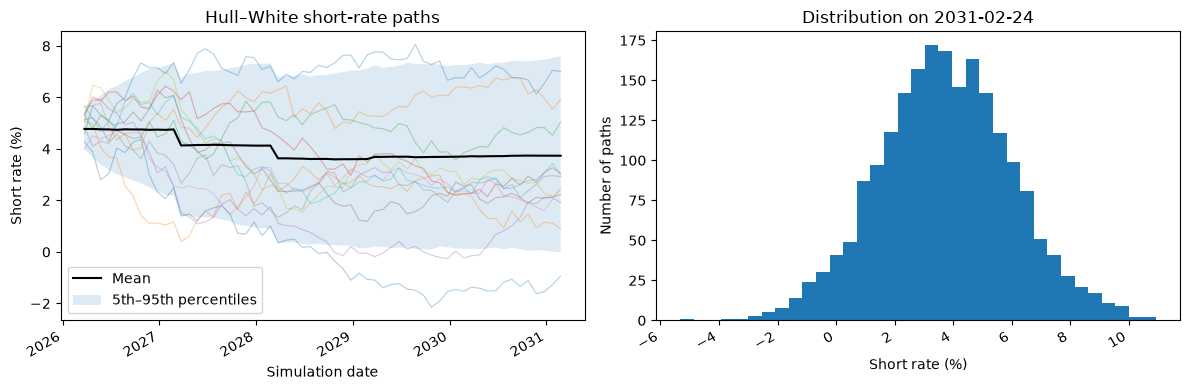

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_dates = pd.to_datetime(paths.columns)
axes[0].plot(plot_dates, paths.iloc[:12].T * 100, alpha=0.35, linewidth=0.8)
axes[0].plot(summary.index, summary["mean"] * 100, color="black", label="Mean")
axes[0].fill_between(
    summary.index,
    summary["p05"] * 100,
    summary["p95"] * 100,
    alpha=0.15,
    label="5th–95th percentiles",
)
axes[0].set(
    title="Hull–White short-rate paths",
    xlabel="Simulation date",
    ylabel="Short rate (%)",
)
axes[0].legend()
axes[1].hist(terminal_rates * 100, bins=35)
axes[1].set(
    title=f"Distribution on {dates[-1]}",
    xlabel="Short rate (%)",
    ylabel="Number of paths",
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


The shaded range contains the 5th–95th percentiles of rates at each date.
It describes variation across paths; the uncertainty in the estimated mean
is measured separately below. Gaussian dynamics permit negative short rates.

## Sampling precision and reproducibility

Repeating a run with the same inputs, grid, path count, seed and implementation
reproduces its paths. A second seed provides a comparison of empirical moments.
For independent paths, the sample standard deviation divided by the square
root of the path count estimates the standard error of the mean. Increasing
path count addresses sampling error; refining the grid addresses Euler bias.


In [5]:
repeated, _, _ = simulate(simulation_config)
other_config = qs.SimulationConfiguration.from_dict({**simulation_spec, "seed": 43})
other_paths, _, _ = simulate(other_config)
seed_comparison = []
for seed, frame in [(42, paths), (42, repeated), (43, other_paths)]:
    terminal_sample = frame.iloc[:, -1]
    standard_error = terminal_sample.std() / len(terminal_sample) ** 0.5
    seed_comparison.append(
        {
            "seed": seed,
            "matches_first_run": frame.equals(paths),
            "terminal_mean": terminal_sample.mean(),
            "mean_standard_error": standard_error,
        }
    )
pd.DataFrame(seed_comparison)


Simulation(market_index='SOFR', n_paths=2048) | average time step: 0.08337899543378996
Simulation(market_index='SOFR', n_paths=2048) | average time step: 0.08337899543378996


,seed,matches_first_run,terminal_mean,mean_standard_error
0,42,True,0.037379,0.000504
1,42,True,0.037379,0.000504
2,43,False,0.037910,0.000517


## Calibration and a moment check

The calibration table gives target option prices, individual fitted prices
and absolute short-rate sigmas. The implementation assembles independently
fitted constant sigmas into a piecewise schedule. Its reported fit residuals
refer to those individual solves. We also check that the selected ATM strikes
lie inside the supplied 3.5%–5.5% smiles.

For the Euler factor, variance follows
$v_{i+1}=(1-\alpha\Delta t_i)^2v_i+\sigma_i^2\Delta t_i$.
The shift uses a separate continuous-OU variance recursion,
$\bar v_{i+1}=e^{-2\alpha\Delta t_i}\bar v_i+
\sigma_i^2(1-e^{-2\alpha\Delta t_i})/(2\alpha)$, and
$\phi_i=f(0,t_i)+\bar v_i/2$. We reconstruct both quantities and compare the
sample mean and standard deviation with the resulting moments.


In [6]:
import math
import numpy as np
from IPython.display import display

assert paths.equals(repeated)
assert not paths.equals(other_paths)
assert paths.shape == (simulation_spec["n_paths"], 60)
assert np.isfinite(paths.to_numpy()).all()
assert calibration is not None and not calibration.empty
assert calibration["price_error"].abs().max() < 1e-8
assert calibration["effective_strike"].between(0.035, 0.055).all()
assert calibration["calibrated_sigma"].ge(0).all()
print(
    f"Maximum calibration price error: {calibration['price_error'].abs().max():.3e} per unit notional."
)
display(calibration[["expiry", "market_vol", "calibrated_sigma", "price_error"]])

alpha = simulation_spec["model"]["HullWhite"]["alpha"]
sigma_schedule = list(zip(calibration["t"], calibration["calibrated_sigma"]))
moments = []
previous_time = 0.0
euler_variance = 0.0
continuous_variance = 0.0
context = qs.PricingContext(
    quotes=market.quotes, curves=market.curves, csa_policy=market.csa_policy
)
with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    for date in dates:
        time = qs.DayCounter.Actual365.year_fraction(ref, date)
        step = time - previous_time
        sigma = sigma_schedule[0][1]
        for breakpoint, value in sigma_schedule:
            if breakpoint > time:
                break
            sigma = value
        euler_variance = (1 - alpha * step) ** 2 * euler_variance + sigma**2 * step
        decay = math.exp(-2 * alpha * step)
        continuous_variance = decay * continuous_variance + sigma**2 * (1 - decay) / (
            2 * alpha
        )
        discount_today = curve.discount_factor(date)
        discount_tomorrow = curve.discount_factor(date + "1D")
        one_day_year_fraction = 1 / 365
        one_day_forward = (
            -math.log(discount_tomorrow / discount_today) / one_day_year_fraction
        )
        moments.append(
            {
                "date": str(date),
                "expected_mean": one_day_forward + continuous_variance / 2,
                "euler_standard_deviation": math.sqrt(euler_variance),
            }
        )
        previous_time = time
moments = pd.DataFrame(moments).set_index("date")
moments["sample_mean"] = paths.mean()
moments["sample_standard_deviation"] = paths.std()
moments["mean_standard_error"] = moments["sample_standard_deviation"] / math.sqrt(
    len(paths)
)
moments["mean_error_in_standard_errors"] = (
    moments["sample_mean"] - moments["expected_mean"]
) / moments["mean_standard_error"]
terminal = moments.iloc[-1]
assert abs(terminal["mean_error_in_standard_errors"]) < 5
assert math.isclose(
    terminal["sample_standard_deviation"],
    terminal["euler_standard_deviation"],
    rel_tol=0.08,
)
moments.iloc[[0, 11, 35, -1]]


Maximum calibration price error: 9.134e-13 per unit notional.


,expiry,market_vol,calibrated_sigma,price_error
0,3M,0.352669,0.016971,8.063775e-13
1,6M,0.332669,0.016093,-5.464518e-13
2,1Y,0.300653,0.012945,8.792669e-13
3,2Y,0.273404,0.010585,-6.567013e-15
4,3Y,0.241917,0.009710,-9.250782e-14
5,5Y,0.218062,0.009456,-5.036325e-13
6,7Y,0.209123,0.008608,2.100837e-13
7,10Y,0.198007,0.008798,8.227548e-13
8,12Y,0.187935,0.008698,-9.133941e-13


,expected_mean,euler_standard_deviation,sample_mean,sample_standard_deviation,mean_standard_error,mean_error_in_standard_errors
date,,,,,,
2026-03-24,0.047888,0.004700,0.047757,0.004612,0.000102,-1.286711
2027-02-24,0.048002,0.015835,0.047602,0.015828,0.000350,-1.144588
2029-02-24,0.036920,0.021249,0.036108,0.020997,0.000464,-1.750850
2031-02-24,0.037831,0.023253,0.037379,0.022825,0.000504,-0.895029


The moment comparison assesses sampling variation relative to the implemented
recursions. Grid refinement is a separate experiment because it changes the
Euler evolution. Calibration to pricing instruments also leaves model-choice
risk when applying these dynamics to other payoffs.

These stored simulations are generated numerically through `f64` and expose
no calibration risk pillars. Model-backed scripting and XVA retain a separate
differentiation workflow.


To study precision, increase `n_paths`, refine the date grid and compare
several seeds. Copying the full path matrix uses memory proportional to paths
times dates; selected summaries can be exported with ordinary pandas methods.

The [XVA notebook](../cva/xva.ipynb) uses future market states to value
contracts and calculate exposure. [Scripting](../scripting/scripted_cashflows.ipynb)
expresses those contracts as dated observation and payment events.
